# **Mini Projet : Correspondances analysis (CA)**


## **Specialty:** ISI


In [ ]:
# Install required libraries
!pip install prince matplotlib seaborn pandas numpy scipy -q

import numpy as np
import pandas as pd
from scipy.linalg import svd
import matplotlib.pyplot as plt



# **Tableau de Contingence**

In [ ]:
data = np.array([
    [68, 119, 26,  7],
    [15,  54, 14, 10],
    [ 5,  29, 14, 16],
    [20,  84, 17, 94]
])

ligne_labels  = ['Brown', 'Hazel', 'Green', 'Blue']
col_labels = ['Brown', 'Dark', 'Red', 'Blond']

df = pd.DataFrame(data, index=ligne_labels, columns=col_labels)
n  = data.sum()

total_lignes = df.sum(axis=1)
total_colonnes = df.sum(axis=0)

df['Total lignes'] = df.sum(axis=1)
df.loc['Total colonne'] = df.sum(axis=0)




#affichage
print("Le nombre total d'observations:",n)
df.style.set_properties(**{
    'text-align': 'center',
    'border': '1px solid black',
    'padding': '6px'
}).set_table_styles([
    {'selector': 'caption',
     'props': [
         ('font-size', '20px'),
         ('font-weight', 'bold'),
         ('color', '#2c3e50'),
         ('text-align', 'center'),
         ('padding', '10px')
     ]}
]).set_caption("Tableau de Contingence ")

Le nombre total d'observations: 592


,Brown,Dark,Red,Blond,Total lignes
Brown,68,119,26,7,220
Hazel,15,54,14,10,93
Green,5,29,14,16,64
Blue,20,84,17,94,215
Total colonne,108,286,71,127,592


# **1. Matrice des fréquences (F = N / n) et probabilités marginales**


## **Matrice des fréquences**

Pour travailler en AFC, on transforme ce tableau en **fréquences relatives**.  
Chaque terme est défini par :

$$
f_{ij} = \frac{n_{ij}}{n}
$$

* $f_{ij}$ représente la **proportion d’individus** appartenant à la ligne (i) et à la colonne (j).



## **Marges de lignes (probabilités des lignes)**

$$
f_i = \frac{\text{total ligne } i}{\text{total général}}
$$



## **Marges de colonnes (probabilités des colonnes)**

$$
f_j = \frac{\text{total colonne } j}{\text{total général}}
$$

In [ ]:
F = data / n

df_F = pd.DataFrame(F, index=ligne_labels, columns=col_labels)

profils_ligne=(total_lignes/n).round(2)
profils_colonnes=(total_colonnes/n).round(2)



#affichage
df_F_margins = pd.DataFrame(F, index=ligne_labels, columns=col_labels)
df_F_margins['Marges de lignes'] = profils_ligne
df_F_margins.loc['Marges de colonnes'] = list(profils_colonnes) + [profils_colonnes.sum()]
print()
print("Matrice des fréquences et Marginal probabilities" )
print(df_F_margins.round(2))

print(f'\n  Total sum of F = {F.sum():.4f}  (must = 1.0)')

display(
    df_F_margins.style.set_properties(**{
        'text-align': 'center',
        'border': '1px solid black',
        'padding': '6px'
    }).format("{:.2f}")
)


Matrice des fréquences et Marginal probabilities
                    Brown  Dark   Red  Blond  Marges de lignes
Brown                0.11  0.20  0.04   0.01              0.37
Hazel                0.03  0.09  0.02   0.02              0.16
Green                0.01  0.05  0.02   0.03              0.11
Blue                 0.03  0.14  0.03   0.16              0.36
Marges de colonnes   0.18  0.48  0.12   0.21              0.99

  Total sum of F = 1.0000  (must = 1.0)


,Brown,Dark,Red,Blond,Marges de lignes
Brown,0.11,0.20,0.04,0.01,0.37
Hazel,0.03,0.09,0.02,0.02,0.16
Green,0.01,0.05,0.02,0.03,0.11
Blue,0.03,0.14,0.03,0.16,0.36
Marges de colonnes,0.18,0.48,0.12,0.21,0.99



# **2. Profils lignes et profils colonnes**



##  **Profils lignes**

On l’obtient en divisant chaque valeur par le total de la ligne correspondant.
$$
\text{Profil ligne_(i)} = \frac{n_{ij}}{total-ligne_i}
$$



## **Profils colonnes**
On l’obtient en divisant chaque valeur par le total de la colonne correspondant.
$$
\text{Profil colonne_(j)} = \frac{n_{ij}}{total-colonne_j}
$$



## **Profils moyens**

### Profil moyen des lignes :


$$
\text{Profil moyen ligne} =  \frac{\text{total colonne } j}{\text{total}}
$$



### Profil moyen des colonnes :

$$
\text{Profil moyen colonne} = \frac{\text{total ligne } i}{\text{total }}
$$



In [ ]:
df = pd.DataFrame(data, index=ligne_labels, columns=col_labels)
print("Tableau de Contingence :")
print(df)

# Total colonnes
total_colonnes = df.sum(axis=0)
print("\n Total colonnes :")
print(pd.DataFrame([total_colonnes], index=["Total colonnes"]))



# PROFILS LIGNES

profil_lignes = df.values / np.sum(df.values, axis=1, keepdims=True)

df_profil_lignes = pd.DataFrame(
    profil_lignes,
    index=ligne_labels,
    columns=col_labels
)
P_l = df_profil_lignes.copy()

# PROFIL MOYEN LIGNES
profil_ligne_moyen = np.sum(df.values, axis=0) / np.sum(df.values)

df_profil_lignes.loc["Profils ligne Moyen"] = profil_ligne_moyen


print("\n Profils lignes :")
df_profil_lignes.round(2)

Tableau de Contingence :
       Brown  Dark  Red  Blond
Brown     68   119   26      7
Hazel     15    54   14     10
Green      5    29   14     16
Blue      20    84   17     94

 Total colonnes :
                Brown  Dark  Red  Blond
Total colonnes    108   286   71    127

 Profils lignes :


,Brown,Dark,Red,Blond
Brown,0.31,0.54,0.12,0.03
Hazel,0.16,0.58,0.15,0.11
Green,0.08,0.45,0.22,0.25
Blue,0.09,0.39,0.08,0.44
Profils ligne Moyen,0.18,0.48,0.12,0.21


In [ ]:
print("Tableau de Contingence :")
print(df)

# TOTAL LIGNES
total_lignes = df.sum(axis=1)
print("\nTotal lignes :")
print(total_lignes)

# PROFILS COLONNES
profil_colonnes = df.values / np.sum(df.values, axis=0, keepdims=True)

df_profil_colonnes = pd.DataFrame(
    profil_colonnes,
    index=ligne_labels,
    columns=col_labels
)
P_col = df_profil_colonnes.copy()


# PROFIL MOYEN COLONNES

profil_colonne_moyen = np.sum(df.values, axis=1) / np.sum(df.values)
df_profil_colonnes.loc["Profils colonne Moyen"] = profil_colonne_moyen

# AFFICHAGE

print("\nProfils colonnes :")
print(df_profil_colonnes.round(2))

Tableau de Contingence :
       Brown  Dark  Red  Blond
Brown     68   119   26      7
Hazel     15    54   14     10
Green      5    29   14     16
Blue      20    84   17     94

Total lignes :
Brown    220
Hazel     93
Green     64
Blue     215
dtype: int64

Profils colonnes :
                       Brown  Dark   Red  Blond
Brown                   0.63  0.42  0.37   0.06
Hazel                   0.14  0.19  0.20   0.08
Green                   0.05  0.10  0.20   0.13
Blue                    0.19  0.29  0.24   0.74
Profils colonne Moyen   0.37  0.16  0.11   0.36


# **Distances entre profils lignes**


In [ ]:
print(df_profil_lignes.round(2))
profils_colonnes = np.sum(df.values, axis=0) / np.sum(df.values)
print(profils_colonnes )
distances_prof_ligne = np.zeros((P_l.shape[0], P_l.shape[0]))

for i in range(P_l.shape[0]):
    for j in range(P_l.shape[0]):
        distances_prof_ligne[i, j] = np.sum(
            (1 /profils_colonnes  ) *(P_l.iloc[i, :] - P_l.iloc[j, :]) ** 2
        )


# AFFICHAGE

print("\n Distance profils lignes :")

D_ligne =pd.DataFrame(
        np.round(distances_prof_ligne, 2),
        index=P_l.index,
        columns=P_l.index)

D_ligne

                     Brown  Dark   Red  Blond
Brown                 0.31  0.54  0.12   0.03
Hazel                 0.16  0.58  0.15   0.11
Green                 0.08  0.45  0.22   0.25
Blue                  0.09  0.39  0.08   0.44
Profils ligne Moyen   0.18  0.48  0.12   0.21
[0.18243243 0.48310811 0.11993243 0.21452703]

 Distance profils lignes :


,Brown,Hazel,Green,Blue
Brown,0.00,0.16,0.61,1.08
Hazel,0.16,0.00,0.20,0.65
Green,0.61,0.20,0.00,0.34
Blue,1.08,0.65,0.34,0.00


# **Distance entre profils ligne et l'origine**

In [ ]:
# distance des profils lignes à l'origine
distances_origine = np.zeros(P_l.shape[0])

for i in range(P_l.shape[0]):
    distances_origine[i] = np.sum(
        (1 / profils_colonnes) *
        (P_l.iloc[i, :] - profils_colonnes) ** 2
    )


print("\nDistance profils lignes à l'origine :")

D_ligne_origine = pd.DataFrame(
    np.round(distances_origine, 2),
    index=P_l.index,
    columns=["Distance origine"])
D_ligne_origine


Distance profils lignes à l'origine :


,Distance origine
Brown,0.25
Hazel,0.08
Green,0.15
Blue,0.31


# **Distances entre profils colonnes**

In [ ]:

# POIDS = PROFILS LIGNES
profils_lignes = df.sum(axis=1) / df.values.sum()
print(profils_lignes)

# MATRICE DES DISTANCES

distances_prof_colonne = np.zeros((P_col.shape[1], P_col.shape[1]))

for i in range(P_col.shape[1]):
    for j in range(P_col.shape[1]):
        distances_prof_colonne[i, j] = np.sum(
            (1 / profils_lignes) *
            (P_col.iloc[:, i] - P_col.iloc[:, j]) ** 2
        )


# AFFICHAGE

print("\n Profils colonnes :")
print(P_col.round(2))

print("\n Distance entre profils colonnes :")
print(pd.DataFrame(
    np.round(distances_prof_colonne, 2),
    index=P_col.columns,
    columns=P_col.columns
))

Brown    0.371622
Hazel    0.157095
Green    0.108108
Blue     0.363176
dtype: float64

 Profils colonnes :
       Brown  Dark   Red  Blond
Brown   0.63  0.42  0.37   0.06
Hazel   0.14  0.19  0.20   0.08
Green   0.05  0.10  0.20   0.13
Blue    0.19  0.29  0.24   0.74

 Distance entre profils colonnes :
       Brown  Dark   Red  Blond
Brown   0.00  0.20  0.43   1.82
Dark    0.20  0.00  0.10   0.98
Red     0.43  0.10  0.00   1.09
Blond   1.82  0.98  1.09   0.00


# **Distance entre profils colonnes et l’origine**


In [ ]:
# DISTANCE À L'ORIGINE

distances_colonne_origine = np.zeros(P_col.shape[1])

for j in range(P_col.shape[1]):
    distances_colonne_origine[j] = np.sum(
        (1 / profils_lignes) *
        (P_col.iloc[:, j] - profils_lignes) ** 2
    )


# AFFICHAGE

print("\n Distance profils colonnes à l'origine :")

print(pd.DataFrame(
    np.round(distances_colonne_origine, 2),
    index=P_col.columns,
    columns=["Distance origine"]
))


 Distance profils colonnes à l'origine :
       Distance origine
Brown              0.30
Dark               0.03
Red                0.13
Blond              0.70


# **AFC**

In [ ]:
!pip install fanalysis

In [ ]:
from fanalysis.ca import CA

# création de l'AFC
AFC = CA(
    row_labels=ligne_labels,
    col_labels=col_labels
)

# apprentissage sur la matrice de contingence
AFC.fit(df.values)

CA(col_labels=['Brown', 'Dark', 'Red', 'Blond'],
   row_labels=['Brown', 'Hazel', 'Green', 'Blue'])

In [ ]:
import pandas as pd
import numpy as np

# valeurs propres
eigenvalues = AFC.eig_[0]

# pourcentage
percent = AFC.eig_[1]

# cumul
cumulative = np.cumsum(percent)

# tableau final
df_eigen = pd.DataFrame({
    "Valeur propre": eigenvalues,
    "Inertie (%)": percent,
    "Cumul (%)": cumulative
},
index=[f"Axe {i+1}" for i in range(len(eigenvalues))])

print("\n Tableau des valeurs propres :")
print(df_eigen.round(2))




 Tableau des valeurs propres :
       Valeur propre  Inertie (%)  Cumul (%)
Axe 1           0.21        89.37      89.37
Axe 2           0.02         9.51      98.89
Axe 3           0.00         1.11     100.00


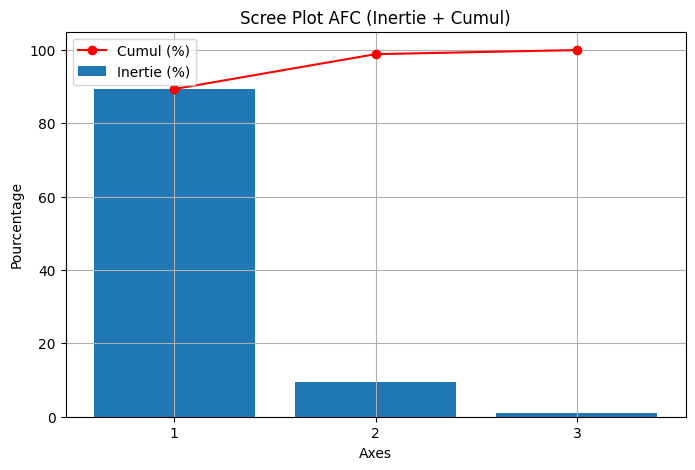

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# données AFC
eigenvalues = AFC.eig_[1]        # % inertie
cumulative = np.cumsum(eigenvalues)

axes = np.arange(1, len(eigenvalues) + 1)

plt.figure(figsize=(8,5))

# barres = inertie
plt.bar(axes, eigenvalues, label="Inertie (%)")

# ligne = cumul
plt.plot(axes, cumulative, marker='o', color='red', label="Cumul (%)")

plt.xticks(axes)
plt.xlabel("Axes")
plt.ylabel("Pourcentage")
plt.title("Scree Plot AFC (Inertie + Cumul)")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
df_cols = AFC.col_topandas()
df_cols.columns

Index(['col_coord_dim1', 'col_coord_dim2', 'col_coord_dim3',
       'col_contrib_dim1', 'col_contrib_dim2', 'col_contrib_dim3',
       'col_cos2_dim1', 'col_cos2_dim2', 'col_cos2_dim3'],
      dtype='object')

In [ ]:
# Coordonnées des profils colonnes

print(df_cols)

       col_coord_dim1  col_coord_dim2  col_coord_dim3  col_contrib_dim1  \
Brown       -0.504562        0.214820       -0.055509         22.246324   
Dark        -0.148253       -0.032666        0.048804          5.085995   
Red         -0.129523       -0.319642       -0.083151          0.963737   
Blond        0.835348        0.069579       -0.016215         71.703943   

       col_contrib_dim2  col_contrib_dim3  col_cos2_dim1  col_cos2_dim2  \
Brown         37.877386         21.633047       0.837962       0.151896   
Dark           2.319381         44.283813       0.864364       0.041965   
Red           55.130519         31.912501       0.133291       0.811774   
Blond          4.672715          2.170639       0.992738       0.006887   

       col_cos2_dim3  
Brown       0.010142  
Dark        0.093671  
Red         0.054934  
Blond       0.000374  


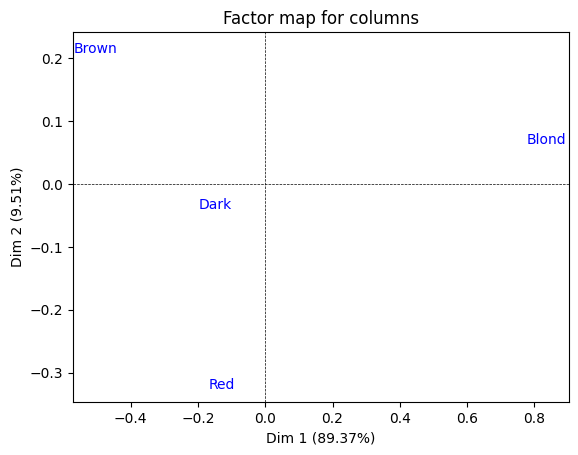

In [ ]:
# Mapping des profils colonnes
AFC.mapping_col(num_x_axis=1, num_y_axis=2)

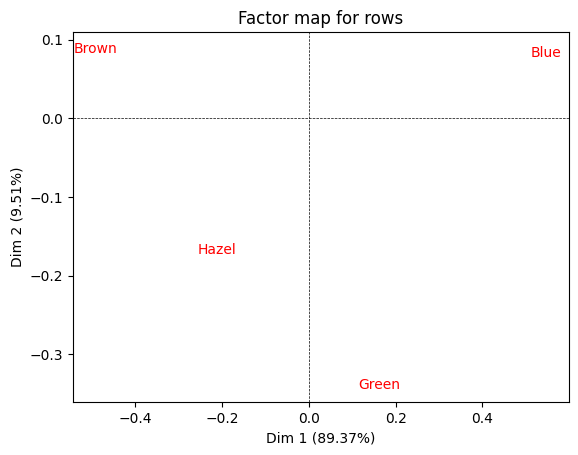

In [ ]:
# Mapping des profils lignes
AFC.mapping_row(num_x_axis=1, num_y_axis=2)

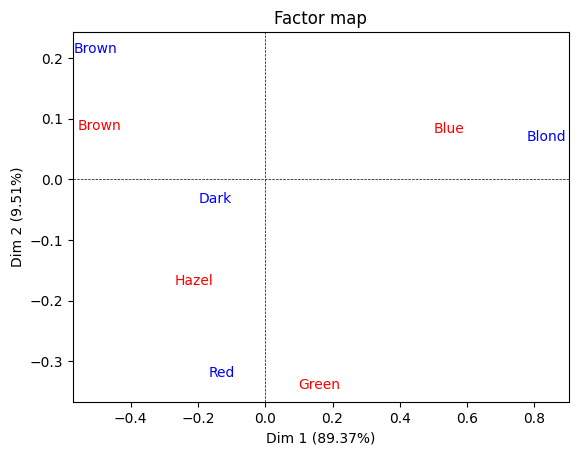

In [ ]:
# Mapping simultané des profils lignes et colonnes
AFC.mapping(num_x_axis=1, num_y_axis=2)

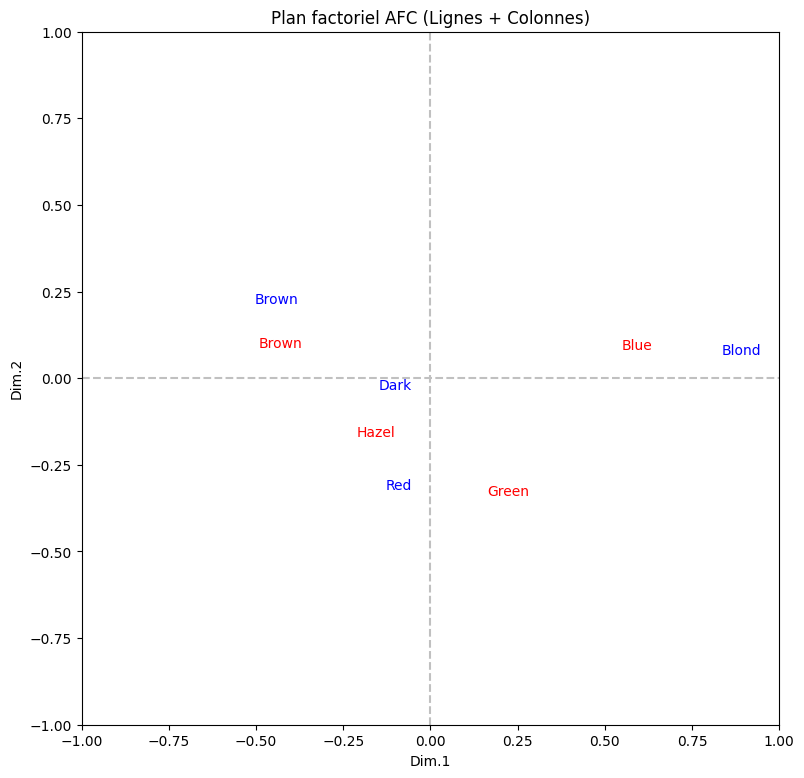

In [ ]:

# PLAN FACTORIEL

fig, ax = plt.subplots(figsize=(9,9))

ax.axis([-1, +1, -1, +1])
ax.plot([-1, +1], [0, 0], color='silver', linestyle='--')
ax.plot([0, 0], [-1, +1], color='silver', linestyle='--')

ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Plan factoriel AFC (Lignes + Colonnes)")


# PROFILS LIGNES (rouge)

for i in range(df.shape[0]):
    ax.text(
        AFC.row_coord_[i, 0],
        AFC.row_coord_[i, 1],
        df.index[i],
        color='red'
    )


# PROFILS COLONNES (bleu)

for j in range(df.shape[1]):
    ax.text(
        AFC.col_coord_[j, 0],
        AFC.col_coord_[j, 1],
        df.columns[j],
        color='blue'
    )

plt.show()

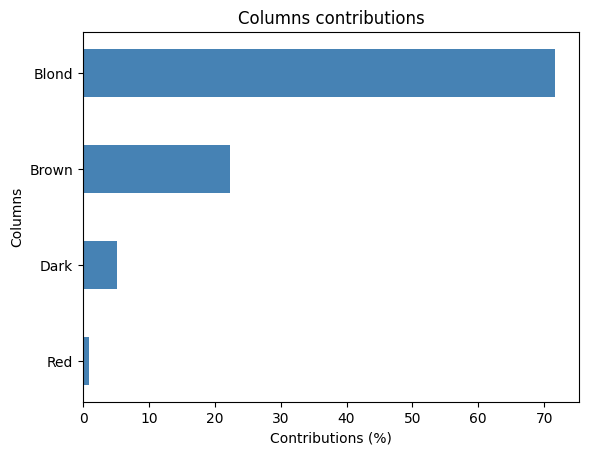

In [ ]:
# Classement des points colonnes en fonction de leur contribution au 1er axe
# Le paramètre de la méthode plot_col_contrib indique que c'est pour l'axe numéro 1 que les contributions sont ici
# représentées
AFC.plot_col_contrib(num_axis=1)

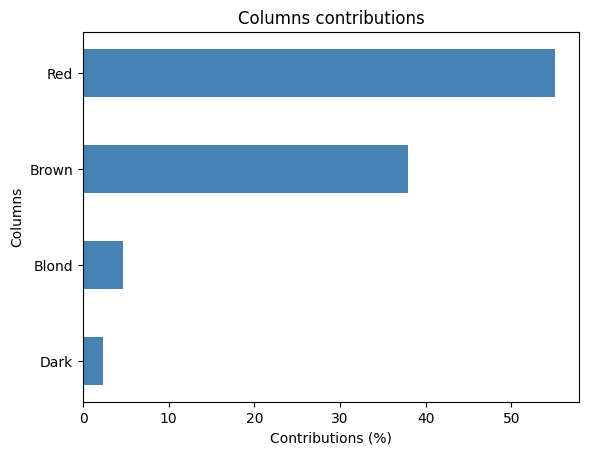

In [ ]:
AFC.plot_col_contrib(num_axis=2)

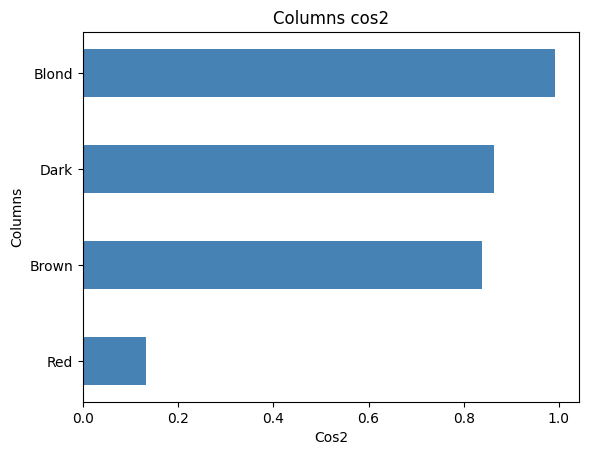

In [ ]:
# Classement des points colonnes en fonction de leur cos2 sur le 1er axe
AFC.plot_col_cos2(num_axis=1)

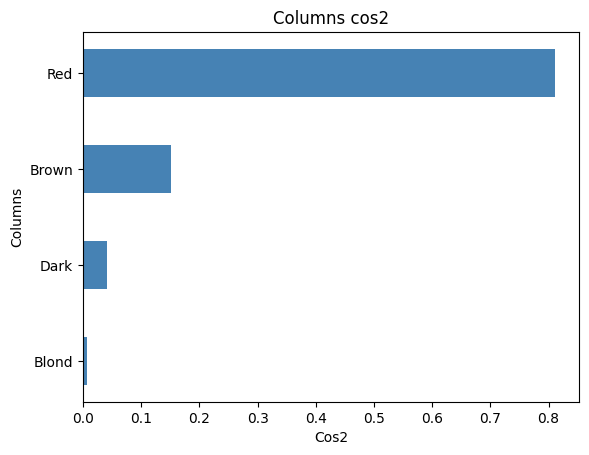

In [ ]:
# Classement des points lignes en fonction de leur cos2 sur le 2eme axe
AFC.plot_col_cos2(num_axis=2)